In [1]:
import pandas as pd
import sqlite3 
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df=pd.read_csv('india-districts-census-2011.csv')

In [3]:
df['State name'].unique()

array(['JAMMU AND KASHMIR', 'HIMACHAL PRADESH', 'PUNJAB', 'CHANDIGARH',
       'UTTARAKHAND', 'HARYANA', 'NCT OF DELHI', 'RAJASTHAN',
       'UTTAR PRADESH', 'BIHAR', 'SIKKIM', 'ARUNACHAL PRADESH',
       'NAGALAND', 'MANIPUR', 'MIZORAM', 'TRIPURA', 'MEGHALAYA', 'ASSAM',
       'WEST BENGAL', 'JHARKHAND', 'ORISSA', 'CHHATTISGARH',
       'MADHYA PRADESH', 'GUJARAT', 'DAMAN AND DIU',
       'DADRA AND NAGAR HAVELI', 'MAHARASHTRA', 'ANDHRA PRADESH',
       'KARNATAKA', 'GOA', 'LAKSHADWEEP', 'KERALA', 'TAMIL NADU',
       'PONDICHERRY', 'ANDAMAN AND NICOBAR ISLANDS'], dtype=object)

# Data Cleaning

In [6]:
df.drop_duplicates(inplace=True)
df.fillna(0,inplace=True)
df

,District code,State name,District name,Population,Male,Female,Literate,Male_Literate,Female_Literate,SC,...,Power_Parity_Rs_90000_150000,Power_Parity_Rs_45000_150000,Power_Parity_Rs_150000_240000,Power_Parity_Rs_240000_330000,Power_Parity_Rs_150000_330000,Power_Parity_Rs_330000_425000,Power_Parity_Rs_425000_545000,Power_Parity_Rs_330000_545000,Power_Parity_Above_Rs_545000,Total_Power_Parity
0,1,JAMMU AND KASHMIR,Kupwara,870354,474190,396164,439654,282823,156831,1048,...,94,588,71,101,172,74,10,84,15,1119
1,2,JAMMU AND KASHMIR,Badgam,753745,398041,355704,335649,207741,127908,368,...,126,562,72,89,161,96,28,124,18,1066
2,3,JAMMU AND KASHMIR,Leh(Ladakh),133487,78971,54516,93770,62834,30936,488,...,46,122,15,22,37,20,14,34,17,242
3,4,JAMMU AND KASHMIR,Kargil,140802,77785,63017,86236,56301,29935,18,...,27,114,12,18,30,19,3,22,7,214
4,5,JAMMU AND KASHMIR,Punch,476835,251899,224936,261724,163333,98391,556,...,78,346,35,50,85,59,8,67,12,629
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
635,636,PONDICHERRY,Mahe,41816,19143,22673,36470,16610,19860,144,...,2316,4309,1370,838,2208,576,978,1554,1446,10027
636,637,PONDICHERRY,Karaikal,200222,97809,102413,154916,79903,75013,35348,...,1063,2408,665,340,1005,246,483,729,341,4890
637,638,ANDAMAN AND NICOBAR ISLANDS,Nicobars,36842,20727,16115,25332,15397,9935,0,...,685,1895,212,134,346,70,120,190,84,3151
638,639,ANDAMAN AND NICOBAR ISLANDS,North AND Middle Andaman,105597,54861,50736,78683,43186,35497,0,...,685,1895,212,134,346,70,120,190,84,3151


In [7]:
df.columns=df.columns.str.lower()
df.columns
df.columns=df.columns.str.replace(' ','_')
df.rename(columns={'others_religions':'other_religion'},inplace=True)
df

,district_code,state_name,district_name,population,male,female,literate,male_literate,female_literate,sc,...,power_parity_rs_90000_150000,power_parity_rs_45000_150000,power_parity_rs_150000_240000,power_parity_rs_240000_330000,power_parity_rs_150000_330000,power_parity_rs_330000_425000,power_parity_rs_425000_545000,power_parity_rs_330000_545000,power_parity_above_rs_545000,total_power_parity
0,1,JAMMU AND KASHMIR,Kupwara,870354,474190,396164,439654,282823,156831,1048,...,94,588,71,101,172,74,10,84,15,1119
1,2,JAMMU AND KASHMIR,Badgam,753745,398041,355704,335649,207741,127908,368,...,126,562,72,89,161,96,28,124,18,1066
2,3,JAMMU AND KASHMIR,Leh(Ladakh),133487,78971,54516,93770,62834,30936,488,...,46,122,15,22,37,20,14,34,17,242
3,4,JAMMU AND KASHMIR,Kargil,140802,77785,63017,86236,56301,29935,18,...,27,114,12,18,30,19,3,22,7,214
4,5,JAMMU AND KASHMIR,Punch,476835,251899,224936,261724,163333,98391,556,...,78,346,35,50,85,59,8,67,12,629
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
635,636,PONDICHERRY,Mahe,41816,19143,22673,36470,16610,19860,144,...,2316,4309,1370,838,2208,576,978,1554,1446,10027
636,637,PONDICHERRY,Karaikal,200222,97809,102413,154916,79903,75013,35348,...,1063,2408,665,340,1005,246,483,729,341,4890
637,638,ANDAMAN AND NICOBAR ISLANDS,Nicobars,36842,20727,16115,25332,15397,9935,0,...,685,1895,212,134,346,70,120,190,84,3151
638,639,ANDAMAN AND NICOBAR ISLANDS,North AND Middle Andaman,105597,54861,50736,78683,43186,35497,0,...,685,1895,212,134,346,70,120,190,84,3151


In [8]:
selected_columns1=['district_code','state_name','district_name','population','male','female','literate','male_literate','female_literate']
selected_columns2=['district_code','workers','male_workers','female_workers','non_workers']
selected_columns3=['district_code','hindus','muslims','christians','sikhs','buddhists','jains','other_religion','religion_not_stated']
df_population=df[selected_columns1]
df_employment=df[selected_columns2]
df_religion=df[selected_columns3]
try:
    conn = sqlite3.connect("Census.db")  
    cursor = conn.cursor()

    # PopulationData Table
    cursor.execute('''
        CREATE TABLE IF NOT EXISTS PopulationData (
            district_code INTEGER PRIMARY KEY,
            state_name TEXT NOT NULL,
            district_name TEXT NOT NULL,
            population INTEGER NOT NULL,
            male INTEGER NOT NULL,
            female INTEGER NOT NULL,
            literate INTEGER NOT NULL,
            male_literate INTEGER NOT NULL,
            female_literate INTEGER NOT NULL
        )
    ''')

    # EmploymentData Table
    cursor.execute('''
        CREATE TABLE IF NOT EXISTS EmploymentData (
            district_code INTEGER PRIMARY KEY,
            workers INTEGER NOT NULL,
            male_workers INTEGER NOT NULL,
            female_workers INTEGER NOT NULL,
            non_workers INTEGER NOT NULL,
            FOREIGN KEY (district_code) REFERENCES PopulationData(district_code)
        )
    ''')

    # ReligionData Table
    cursor.execute('''
        CREATE TABLE IF NOT EXISTS ReligionData (
            district_code INTEGER PRIMARY KEY,
            hindus INTEGER NOT NULL,
            muslims INTEGER NOT NULL,
            christians INTEGER NOT NULL,
            sikhs INTEGER NOT NULL,
            buddhists INTEGER NOT NULL,
            jains INTEGER NOT NULL,
            other_religion INTEGER NOT NULL,
            religion_not_stated INTEGER NOT NULL,
            FOREIGN KEY (district_code) REFERENCES PopulationData(district_code)
        )
    ''')

    conn.commit()
    print("Tables created successfully!")

    try:
        df_population.to_sql("PopulationData", conn, if_exists="replace", index=False)
        print("PopulationData inserted successfully!")
    except Exception as e:
        print("Error inserting PopulationData:", e)

    
    try:
        df_employment.to_sql("EmploymentData", conn, if_exists="replace", index=False)
        print("EmploymentData inserted successfully!")
    except Exception as e:
        print("Error inserting EmploymentData:", e)


    try:
        df_religion.to_sql("ReligionData", conn, if_exists="replace", index=False)
        print("ReligionData inserted successfully!")
    except Exception as e:
        print("Error inserting ReligionData:", e)

except sqlite3.Error as e:
    print("SQLite Error:", e)

Tables created successfully!
PopulationData inserted successfully!
EmploymentData inserted successfully!
ReligionData inserted successfully!


In [4]:
class Census:
    def __init__(self):
        self.conn=sqlite3.connect("Census.db")
    def fetch_query(self,query):
        try:
            data_frame=pd.read_sql_query(query,self.conn)
            return data_frame
        except sqlite3.Error as e:
            print('Error',e)

In [5]:
class Analyzer:
    def view_overall_census_data(self):
        try:
            query_population = """Select p.state_name,SUM(p.population) AS total_population,SUM(p.male) AS total_male,SUM(p.female) AS total_female,
            SUM(p.literate) AS total_literate,SUM(p.male_literate) AS total_male_literate,SUM(p.female_literate) AS total_female_literate from
            populationData as p GROUP BY p.state_name;"""
            population_data = obj_census.fetch_query(query_population)
            if population_data.empty:
                print("No Population Data Found")
            else:
                print("Population Data:")
                print(population_data.to_string(index=False)) 
                print("\n" + "-"*50 + "\n") 
    
            
            query_employment="""Select p.state_name,sum(p.population) as total_population,sum(e.workers) as workers,sum(e.male_workers) as male_workers,sum(e.female_workers) as female_workers from
            populationData as p INNER JOIN EmploymentData as e ON p.district_code=e.district_code GROUP BY p.state_name"""
            
            employment_data = obj_census.fetch_query(query_employment)
    
            if employment_data.empty:
                print("No Employment Data Found")
            else:
                print("Employment Data:")
                print(employment_data.to_string(index=False)) 
                print("\n" + "-"*50 + "\n") 
    
            query_religion="""Select state_name,sum(hindus) as total_hindus,sum(muslims) as total_muslims,sum(christians) as total_christians,
            sum(sikhs) as total_sikhs,sum(buddhists) as total_buddhists,sum(jains) as total_jains,sum(other_religion)
            as total_other_religions,sum(religion_not_stated) as 
            total_religion_not_stated from populationData INNER JOIN religionData on populationData.district_code=religionData.district_code GROUP BY state_name"""
            
            religion_data = obj_census.fetch_query(query_religion)
    
            if religion_data.empty:
                print("No Religion Data Found")
            else:
                print("Religion Data:")
                print(religion_data.to_string(index=False))  
                print("\n" + "-"*50 + "\n")
        except Exception as e:
            print('Error',e)
            
    def State_wise_Population(self):
        try:
            query='''Select state_name,sum(population) as total_population from PopulationData group by state_name order by total_population desc'''
            data=obj_census.fetch_query(query)
            plt.figure(figsize=(12,10))
            plt.barh(data['state_name'],data['total_population'])
            plt.xlabel('Total Population')
            plt.ylabel('State')
            plt.title('State-wise Total Population')
            print('Total Population:')
            print(data[['state_name','total_population']].to_string(index=False))
            print('Top 5 States:')
            print(data.head(5).to_string(index=False))
            print('Least 5 States:')
            print(data.tail(5).to_string(index=False))
            plt.show()
        except Exception as e:
            print('Error',e)
    
    def male_female_comparision(self):
        try:
            
            query = 'SELECT state_name, SUM(male) AS total_male, SUM(female) AS total_female FROM PopulationData GROUP BY state_name'
            data = obj_census.fetch_query(query)
        
            plt.figure(figsize=(12, 10))
        
            x = np.arange(len(data['state_name']))  
            width = 0.4  
        
            plt.bar(x - width/2, data['total_male'], color='blue', width=width, label='Male')
            plt.bar(x + width/2, data['total_female'], color='pink', width=width, label='Female')
        
            plt.xticks(x, data['state_name'], rotation=90)
            plt.xlabel("State")
            plt.ylabel("Population")
            plt.title("State-wise Male vs Female Population")
            plt.legend()  
        
            plt.show()
            
        except Exception as e:
            print('Error',e)

    def analyze_literacy_rate(self,show_plot=True):
        try:
            
            query="Select state_name,sum(population) as total_population,sum(literate) as total_literate,sum(male_literate) as total_male_literate,sum(female_literate) as total_female_literate from populationData group by state_name"
            data=obj_census.fetch_query(query)
            plt.figure(figsize=(12,10))
            data['Total_literacy_rate']=(data['total_literate']/data['total_population'])*100
            data['Male_literacy_rate']=(data['total_male_literate']/data['total_population'])*100
            data['Female_literacy_rate']=(data['total_female_literate']/data['total_population'])*100
           
            x=np.arange(len(data['state_name']))
            width=0.3
            bar1=plt.bar(x-width,data['Total_literacy_rate'],width=width,label='Total Literacy Rate',color='c',alpha=0.7)
            bar2=plt.bar(x,data['Male_literacy_rate'],width=width,label='Male Literacy Rate',color='blue',alpha=0.7)
            bar3=plt.bar(x+width,data['Female_literacy_rate'],width=width,label='Female Literacy Rate',color='pink',alpha=0.7)
            
            plt.xlabel('States')
            plt.ylabel('Literacy Rate(%)')
            plt.title('State-Wise Literacy Rates')
            plt.xticks(x,data['state_name'], rotation=90)
            plt.legend()
            plt.grid(axis='y', linestyle='--', alpha=0.5)
            if show_plot:
                print(data[['state_name','Total_literacy_rate','Male_literacy_rate','Female_literacy_rate']].to_string(index=False,formatters={
                    'Total_literacy_rate':'{:0.2f}'.format,'Male_literacy_rate':'{:0.2f}'.format,'Female_literacy_rate':'{:0.2f}'.format
                }))
                literacy_rates = np.array(data['Total_literacy_rate'])
                print("\nLiteracy Rate Statistics:")
                print(f"Mean Literacy Rate: {np.mean(literacy_rates):.2f}%")
                print(f"Median Literacy Rate: {np.median(literacy_rates):.2f}%")
                print(f"Standard Deviation: {np.std(literacy_rates):.2f}%")
                plt.show()
            else:
                plt.close()
            return data['Total_literacy_rate'],data['state_name']
            
        except Exception as e:
            print('Error',e)

    def analyze_employment_rate(self,show_plot=True):
        try:
            
            query='''Select p.state_name,sum(p.population) as total_population,sum(e.workers) as workers,sum(e.male_workers) as male_workers,sum(e.female_workers) as female_workers from
            populationData as p INNER JOIN EmploymentData as e ON p.district_code=e.district_code GROUP BY p.state_name'''
            data=obj_census.fetch_query(query)
            data['Employment_Rate'] =(data['workers'] / (data['total_population'])) * 100
            data['Male_Employment_Rate'] =(data['male_workers'] / (data['total_population'])) * 100
            data['Female_Employment_Rate'] =(data['female_workers'] / (data['total_population'])) * 100
            # Plot settings
            plt.figure(figsize=(12,10))
            width = 0.3
            x = np.arange(len(data['state_name']))
            
            # Plot bars for employment rates
            plt.bar(x-width, data['Employment_Rate'], width=width, label='Total Employment Rate', color='blue')
            plt.bar(x,data['Male_Employment_Rate'], width=width, label='Male Employment Rate', color='green')
            plt.bar(x+width, data['Female_Employment_Rate'], width=width, label='Female Employment Rate', color='red')
            
            # X-axis labels
            plt.xticks(x, data['state_name'],rotation=90)
            # Labels and title
            plt.xlabel('States')
            plt.ylabel('Employment Rate (%)')
            plt.title('State-wise Employment Rates')
            plt.legend()
    
            if show_plot:
                print(data[['state_name', 'Employment_Rate', 'Male_Employment_Rate', 'Female_Employment_Rate']].to_string(index=False,formatters={
                    'Employment_Rate':'{:0.2f}'.format,'Male_Employment_Rate':'{:0.2f}'.format,'Female_Employment_Rate':'{:0.2f}'.format
                }))
                emp_rates = np.array(data['Employment_Rate'])
                print("\nEmployment Rate Statistics:")
                print(f"Mean Employment Rate: {np.mean(emp_rates):.2f}%")
                print(f"Median Employment Rate: {np.median(emp_rates):.2f}%")
                print(f"Standard Deviation: {np.std(emp_rates):.2f}%")
                plt.show()
            else:
                plt.close()
            return data['Employment_Rate']
        except Exception as e:
            print('Error',e)
    
    def analyze_religion_distribution(self):
        try:
            
            query='''Select p.state_name,sum(p.population) as total_population,sum(r.hindus) as total_hindus,sum(r.muslims) as total_muslims,sum(r.christians) as total_christians,
            sum(r.sikhs) as total_sikhs,sum(r.buddhists) as total_buddhists,sum(r.jains) as total_jains,sum(r.other_religion)
            as total_other_religions,sum(r.religion_not_stated) as 
            total_religion_not_stated from populationData as p INNER JOIN religionData as r on p.district_code=r.district_code'''
            data=obj_census.fetch_query(query)
            data['total_hindus(%)']=(data['total_hindus']/data['total_population'])*100
            data['total_muslims(%)']=(data['total_muslims']/data['total_population'])*100
            data['total_christians(%)']=(data['total_christians']/data['total_population'])*100
            data['total_sikhs(%)']=(data['total_sikhs']/data['total_population'])*100
            data['total_buddhists(%)']=(data['total_buddhists']/data['total_population'])*100
            data['total_jains(%)']=(data['total_jains']/data['total_population'])*100
            data['total_other_religions(%)']=(data['total_other_religions']/data['total_population'])*100
            data['total_religion_not_stated(%)']=(data['total_religion_not_stated']/data['total_population'])*100
    
            print(data[['total_hindus(%)', 'total_muslims(%)', 'total_christians(%)', 
                               'total_sikhs(%)', 'total_buddhists(%)', 'total_jains(%)', 'total_other_religions(%)', 
                               'total_religion_not_stated(%)']].to_string(index=False,formatters={
                    'total_hindus(%)':'{:0.2f}'.format,'total_muslims(%)':'{:0.2f}'.format,'total_christians(%)':'{:0.2f}'.format,
                'total_sikhs(%)':'{:0.2f}'.format,'total_buddhists(%)':'{:0.2f}'.format,'total_jains(%)':'{:0.2f}'.format,
                'total_other_religions(%)':'{:0.2f}'.format,'total_religion_not_stated(%)':'{:0.2f}'.format
                }))
            religion_data=np.array([data['total_hindus(%)'].values[0],data['total_muslims(%)'].values[0],data['total_christians(%)'].values[0],data['total_sikhs(%)'].values[0],data['total_buddhists(%)'].values[0],
                                    data['total_jains(%)'].values[0],data['total_other_religions(%)'].values[0], data['total_religion_not_stated(%)'].values[0]])
            my_labels=['Hindus','Muslims','Christians','Sikhs','Buddhists','Jains','Other Religions','Religion Not Stated']
            color=['orange','y','c','b','m','r','pink','green']
            myexplode=[0,0,0.1,0.2,0.4,0.6,0.8,1.0]
            plt.pie(religion_data,labels=my_labels,colors=color,autopct='%0.2f%%',explode=myexplode,labeldistance=1.2)
            plt.legend(loc='lower left',title='Religions')
            plt.show()
        except Exception as e:
            print('Error',e)

    
    def literacy_vs_employment(self):
        try:
            
            literacy_rate,state_name=self.analyze_literacy_rate(show_plot=False)
            employment_rate=self.analyze_employment_rate(show_plot=False)
            plt.figure(figsize=(15, 8))
            
            plt.plot(state_name,employment_rate, marker='o', linestyle='-', color='b', label='Employment Rate')
            plt.plot(state_name, literacy_rate, marker='x', linestyle='--', color='g', label='Literacy Rate')
            
            plt.title('State-wise Employment Rate vs Literacy Rate')
            plt.xlabel('States')
            plt.ylabel('Rate (%)')
            plt.xticks(rotation=90)
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            
            plt.show()
            literacy = np.array(literacy_rate)
            employment = np.array(employment_rate)
            correlation = np.corrcoef(literacy, employment)[0, 1]
            print("\nEmployment vs Literacy Correlation:")
            print(f"Correlation Coefficient: {correlation:0.2f}")
        except Exception as e:
            print('Error',e)

        
    def Visualize_data_for_particular_state(self):
        try:
            state=input('Enter State you want to analyze data of:')
            query=f"""Select p.state_name,p.district_name,p.population,p.literate,p.male_literate,p.female_literate,e.workers,e.male_workers,e.female_workers,r.hindus 
            ,r.muslims,r.christians,
            r.sikhs,r.buddhists,r.jains,r.other_religion,r.religion_not_stated from PopulationData as p INNER JOIN employmentData as e on p.district_code=e.district_code
            INNER JOIN religionData
            as r on p.district_code=r.district_code WHERE state_name='{state.upper()}'"""
            data=obj_census.fetch_query(query)
            plt.figure(figsize=(15,17))
            plt.subplot(2,2,1)
            plt.bar(data['district_name'],data['population'])
            plt.xlabel('Total Population')
            plt.ylabel('District')
            plt.title('District-wise Total Population')
            plt.xticks(rotation=90)
            
            plt.subplot(2,2,2)
            data['Total_literacy_rate']=(data['literate']/data['population'])*100
            data['Male_literacy_rate']=(data['male_literate']/data['population'])*100
            data['Female_literacy_rate']=(data['female_literate']/data['population'])*100
            
            x=np.arange(len(data['district_name']))
            width=0.3
            bar1=plt.bar(x-width,data['Total_literacy_rate'],width=width,label='Total Literacy Rate',color='c',alpha=0.7)
            bar2=plt.bar(x,data['Male_literacy_rate'],width=width,label='Male Literacy Rate',color='blue',alpha=0.7)
            bar3=plt.bar(x+width,data['Female_literacy_rate'],width=width,label='Female Literacy Rate',color='pink',alpha=0.7)
            plt.xlabel('Districts')
            plt.ylabel('Literacy Rate(%)')
            plt.title('District-Wise Literacy Rates')
            plt.xticks(x,data['district_name'], rotation=90)
            plt.legend()
            plt.grid(axis='y', linestyle='--', alpha=0.5)
            
            plt.subplot(2,2,3)
            data['Employment_Rate'] =(data['workers'] / (data['population'])) * 100
            data['Male_Employment_Rate'] =(data['male_workers'] / (data['population'])) * 100
            data['Female_Employment_Rate'] =(data['female_workers'] / (data['population'])) * 100
            # Plot settings
            width = 0.3
            x = np.arange(len(data['district_name']))
            
            # Plot bars for employment rates
            plt.bar(x-width, data['Employment_Rate'], width=width, label='Total Employment Rate', color='blue')
            plt.bar(x,data['Male_Employment_Rate'], width=width, label='Male Employment Rate', color='green')
            plt.bar(x+width, data['Female_Employment_Rate'], width=width, label='Female Employment Rate', color='red')
            
            plt.xticks(x, data['district_name'],rotation=90)
            # Labels and title
            plt.xlabel('Districts')
            plt.ylabel('Employment Rate (%)')
            plt.title('District-wise Employment Rates')
            plt.legend()
    
            plt.subplot(2,2,4)
            data['total_hindus(%)']=(data['hindus']/data['population'])*100
            data['total_muslims(%)']=(data['muslims']/data['population'])*100
            data['total_christians(%)']=(data['christians']/data['population'])*100
            data['total_sikhs(%)']=(data['sikhs']/data['population'])*100
            data['total_buddhists(%)']=(data['buddhists']/data['population'])*100
            data['total_jains(%)']=(data['jains']/data['population'])*100
            data['total_other_religions(%)']=(data['other_religion']/data['population'])*100
            data['total_religion_not_stated(%)']=(data['religion_not_stated']/data['population'])*100
            religion_data=np.array([data['total_hindus(%)'].values[0],data['total_muslims(%)'].values[0],data['total_christians(%)'].values[0],data['total_sikhs(%)'].values[0],data['total_buddhists(%)'].values[0],
                                    data['total_jains(%)'].values[0],data['total_other_religions(%)'].values[0], data['total_religion_not_stated(%)'].values[0]])
            my_labels=['Hindus','Muslims','Christians','Sikhs','Buddhists','Jains','Other Religions','Religion Not Stated']
            color=['orange','y','c','b','m','r','pink','green']
            myexplode=[0,0,0.1,0.2,0.3,0.5,0.7,1.0]
            plt.pie(religion_data,labels=my_labels,colors=color,autopct='%0.2f%%',explode=myexplode,labeldistance=1.2)
            plt.legend(loc='lower left',title='Religions')
            # plt.tight_layout()
            plt.show()
        except Exception as e:
            print('State not Found.Enter Correct State.')


Census Data Analysis Menu:

1. View Overall Census Data

2. View State-wise Population Distribution

3. Compare Male and Female Population

4. Analyze Literacy Rate Trends

5. Analyze Employment Rate Trends

6. Analyze Religion-wise Population Distribution

7. Correlation between Literacy Rate and Employment Rate

8. Visualize Data for a Particular State

9. Exit



Enter your choice:  1


Population Data:
                 state_name  total_population  total_male  total_female  total_literate  total_male_literate  total_female_literate
ANDAMAN AND NICOBAR ISLANDS            380581      202871        177710          294281               164377                 129904
             ANDHRA PRADESH          84580777    42442146      42138631        50556760             28251243               22305517
          ARUNACHAL PRADESH           1383727      713912        669815          766005               439868                 326137
                      ASSAM          31205576    15939443      15266133        19177977             10568639                8609338
                      BIHAR         104099452    54278157      49821295        52504553             31608023               20896530
                 CHANDIGARH           1055450      580663        474787          805438               465346                 340092
               CHHATTISGARH          25545198    12832895  


Enter your choice:  2


Total Population:
                 state_name  total_population
              UTTAR PRADESH         199812341
                MAHARASHTRA         112374333
                      BIHAR         104099452
                WEST BENGAL          91276115
             ANDHRA PRADESH          84580777
             MADHYA PRADESH          72626809
                 TAMIL NADU          72147030
                  RAJASTHAN          68548437
                  KARNATAKA          61095297
                    GUJARAT          60439692
                     ORISSA          41974218
                     KERALA          33406061
                  JHARKHAND          32988134
                      ASSAM          31205576
                     PUNJAB          27743338
               CHHATTISGARH          25545198
                    HARYANA          25351462
               NCT OF DELHI          16787941
          JAMMU AND KASHMIR          12541302
                UTTARAKHAND          10086292
           HIMAC

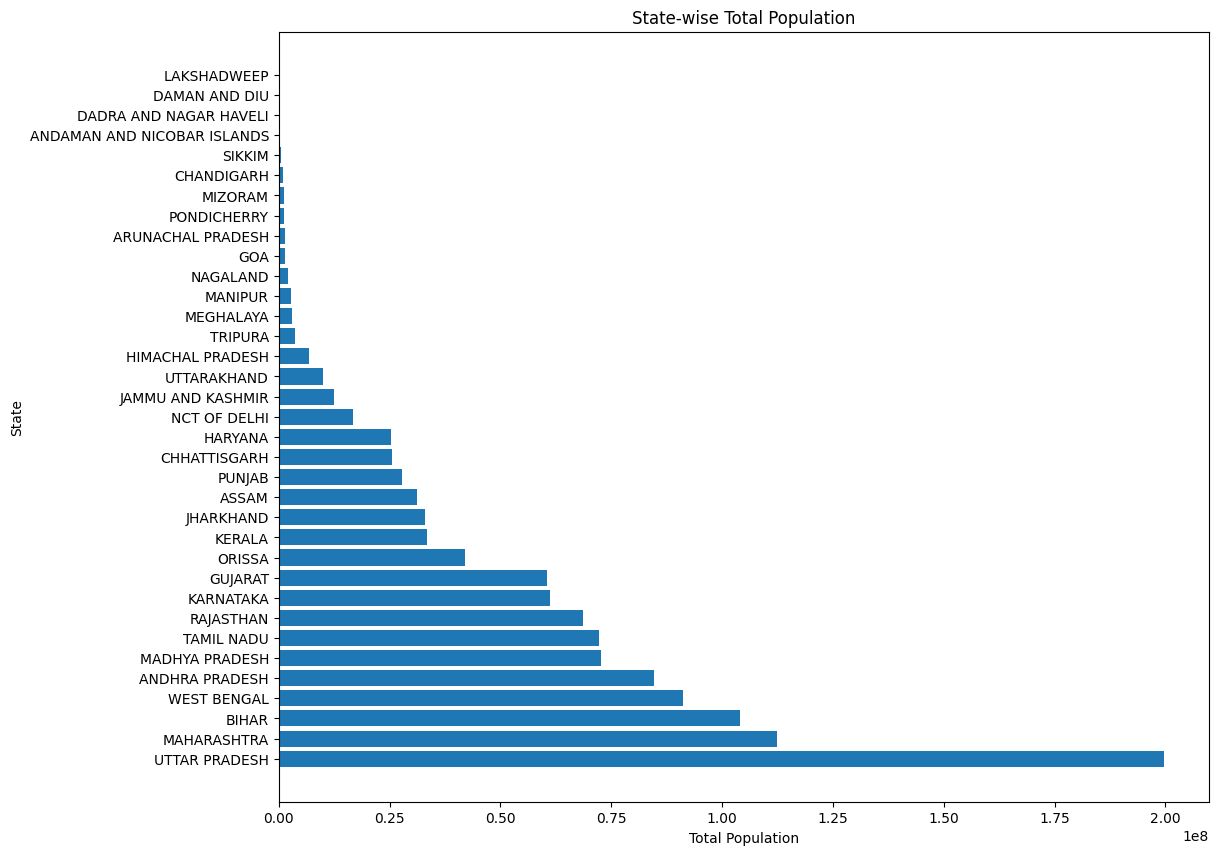


Census Data Analysis Menu:

1. View Overall Census Data

2. View State-wise Population Distribution

3. Compare Male and Female Population

4. Analyze Literacy Rate Trends

5. Analyze Employment Rate Trends

6. Analyze Religion-wise Population Distribution

7. Correlation between Literacy Rate and Employment Rate

8. Visualize Data for a Particular State

9. Exit



Enter your choice:  3


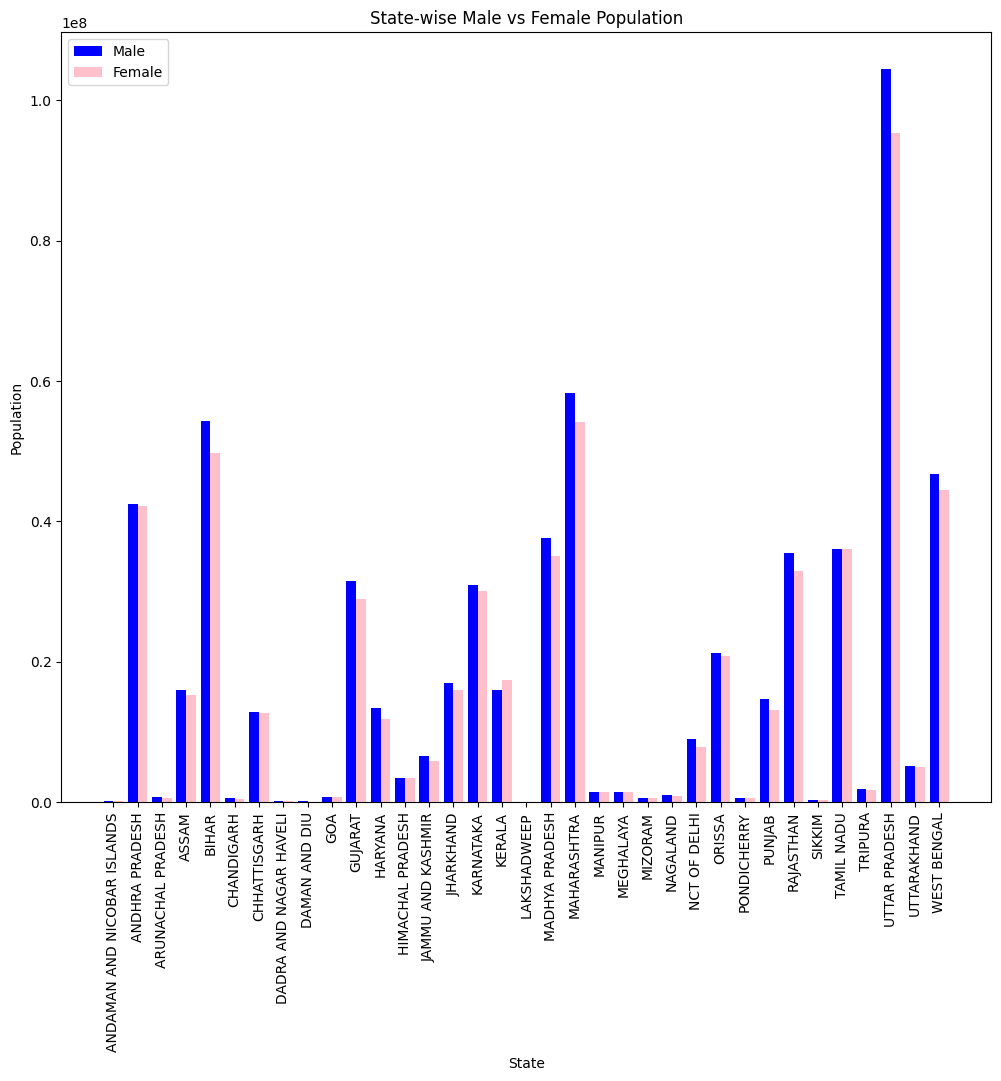


Census Data Analysis Menu:

1. View Overall Census Data

2. View State-wise Population Distribution

3. Compare Male and Female Population

4. Analyze Literacy Rate Trends

5. Analyze Employment Rate Trends

6. Analyze Religion-wise Population Distribution

7. Correlation between Literacy Rate and Employment Rate

8. Visualize Data for a Particular State

9. Exit



Enter your choice:  3


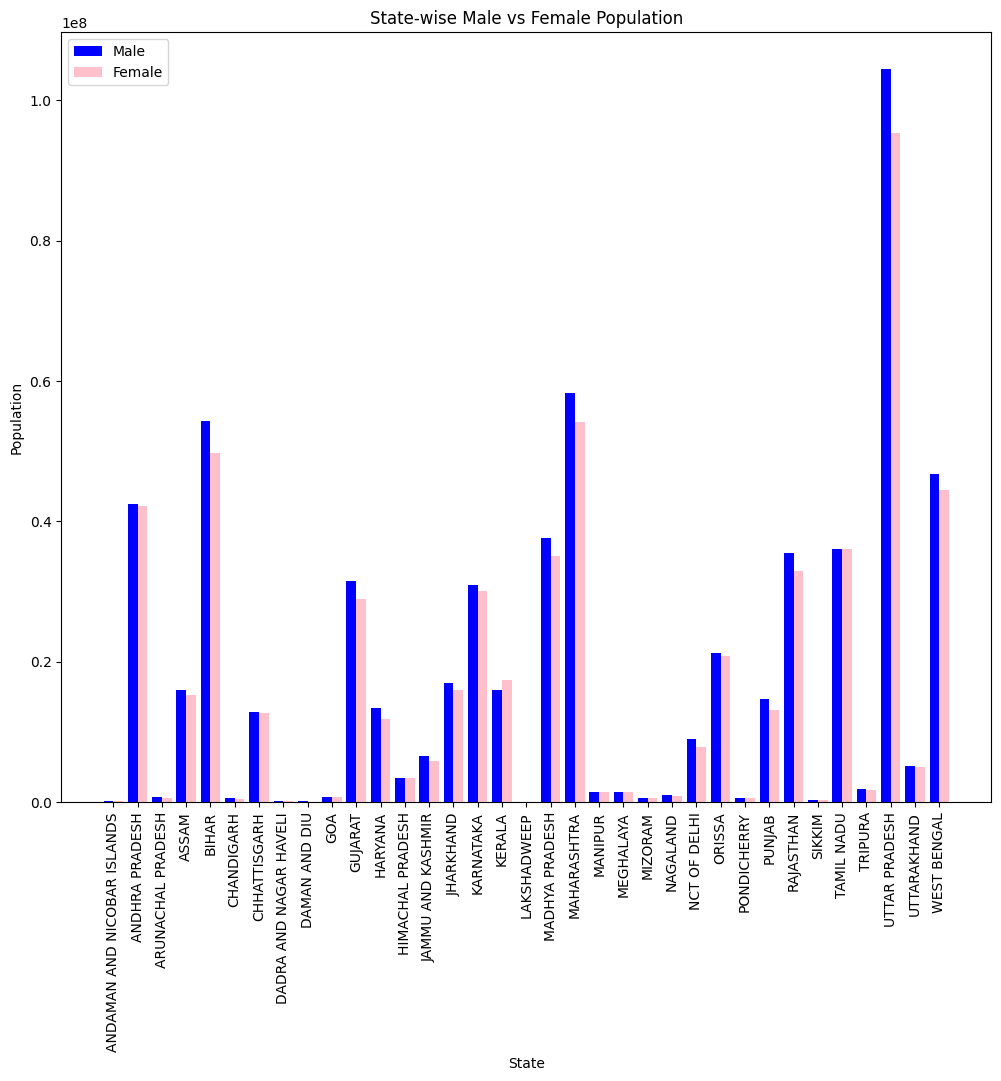


Census Data Analysis Menu:

1. View Overall Census Data

2. View State-wise Population Distribution

3. Compare Male and Female Population

4. Analyze Literacy Rate Trends

5. Analyze Employment Rate Trends

6. Analyze Religion-wise Population Distribution

7. Correlation between Literacy Rate and Employment Rate

8. Visualize Data for a Particular State

9. Exit



Enter your choice:  4


                 state_name Total_literacy_rate Male_literacy_rate Female_literacy_rate
ANDAMAN AND NICOBAR ISLANDS               77.32              43.19                34.13
             ANDHRA PRADESH               59.77              33.40                26.37
          ARUNACHAL PRADESH               55.36              31.79                23.57
                      ASSAM               61.46              33.87                27.59
                      BIHAR               50.44              30.36                20.07
                 CHANDIGARH               76.31              44.09                32.22
               CHHATTISGARH               60.21              34.48                25.73
     DADRA AND NAGAR HAVELI               64.95              41.47                23.48
              DAMAN AND DIU               77.45              51.24                26.21
                        GOA               79.91              42.22                37.69
                    GUJARAT     

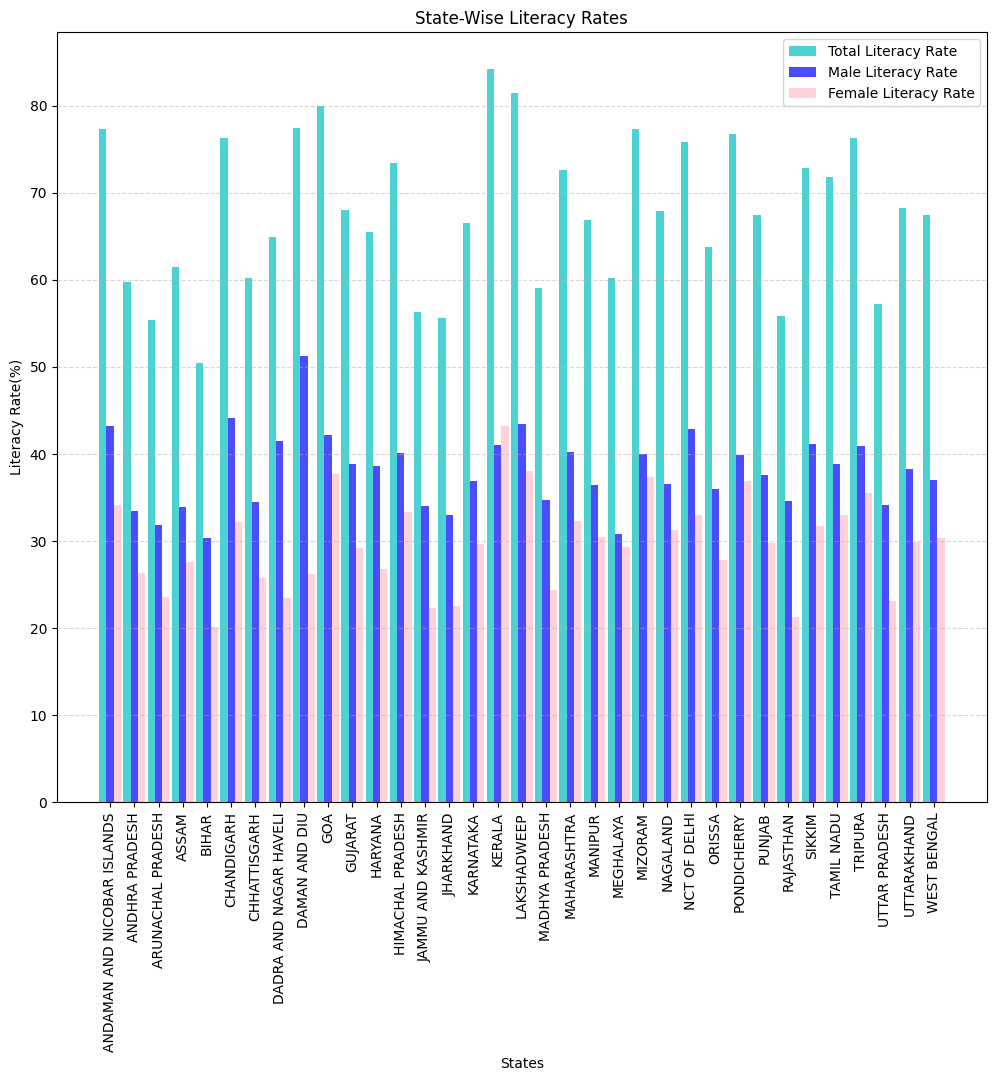


Census Data Analysis Menu:

1. View Overall Census Data

2. View State-wise Population Distribution

3. Compare Male and Female Population

4. Analyze Literacy Rate Trends

5. Analyze Employment Rate Trends

6. Analyze Religion-wise Population Distribution

7. Correlation between Literacy Rate and Employment Rate

8. Visualize Data for a Particular State

9. Exit



Enter your choice:  5


                 state_name Employment_Rate Male_Employment_Rate Female_Employment_Rate
ANDAMAN AND NICOBAR ISLANDS           40.08                31.76                   8.32
             ANDHRA PRADESH           46.61                28.59                  18.02
          ARUNACHAL PRADESH           42.47                25.31                  17.16
                      ASSAM           38.36                27.37                  10.99
                      BIHAR           33.36                24.23                   9.13
                 CHANDIGARH           38.29                31.09                   7.20
               CHHATTISGARH           47.68                27.93                  19.75
     DADRA AND NAGAR HAVELI           45.73                34.71                  11.02
              DAMAN AND DIU           49.86                44.17                   5.69
                        GOA           39.58                28.76                  10.81
                    GUJARAT     

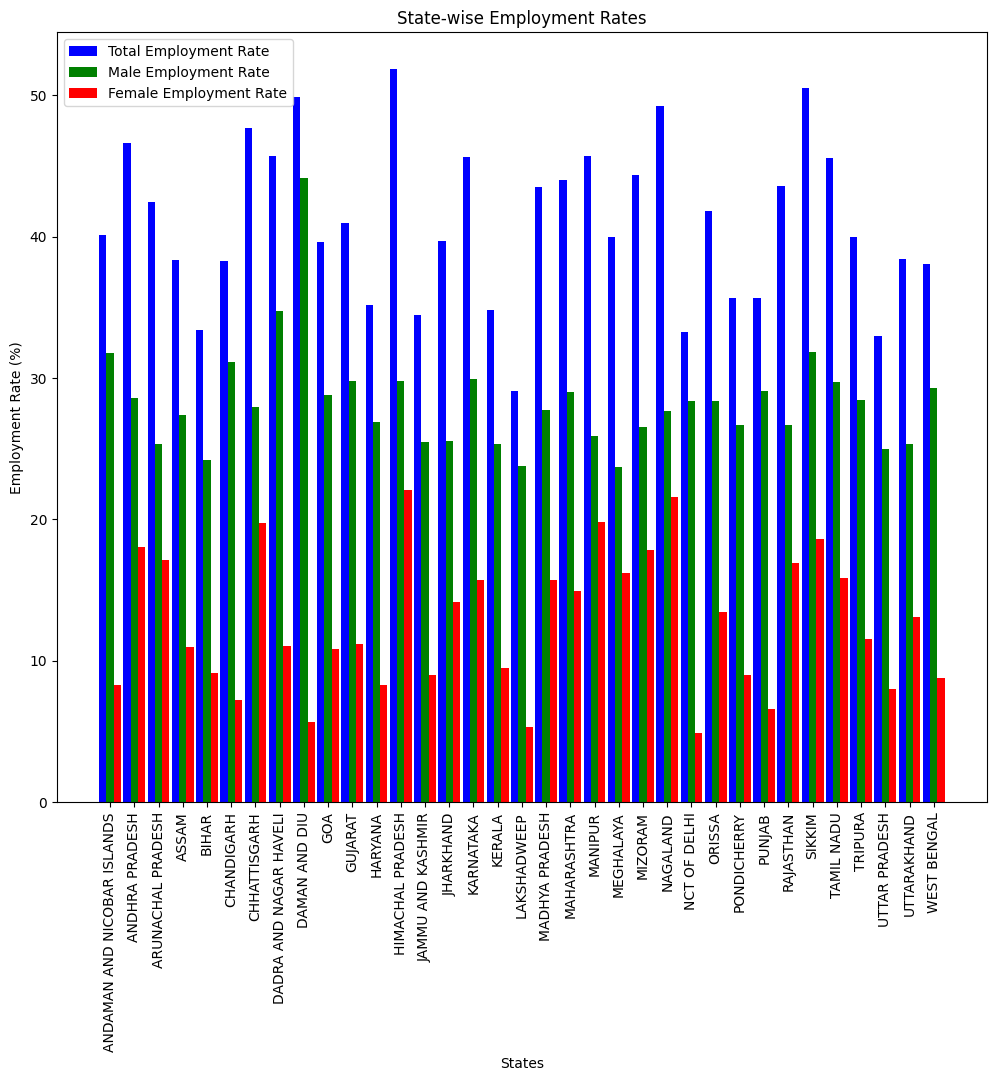


Census Data Analysis Menu:

1. View Overall Census Data

2. View State-wise Population Distribution

3. Compare Male and Female Population

4. Analyze Literacy Rate Trends

5. Analyze Employment Rate Trends

6. Analyze Religion-wise Population Distribution

7. Correlation between Literacy Rate and Employment Rate

8. Visualize Data for a Particular State

9. Exit



Enter your choice:  6


total_hindus(%) total_muslims(%) total_christians(%) total_sikhs(%) total_buddhists(%) total_jains(%) total_other_religions(%) total_religion_not_stated(%)
          79.80            14.23                2.30           1.72               0.70           0.37                     0.66                         0.24


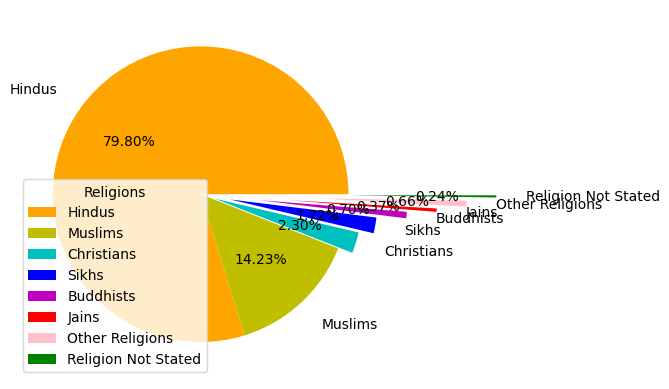


Census Data Analysis Menu:

1. View Overall Census Data

2. View State-wise Population Distribution

3. Compare Male and Female Population

4. Analyze Literacy Rate Trends

5. Analyze Employment Rate Trends

6. Analyze Religion-wise Population Distribution

7. Correlation between Literacy Rate and Employment Rate

8. Visualize Data for a Particular State

9. Exit



Enter your choice:  7


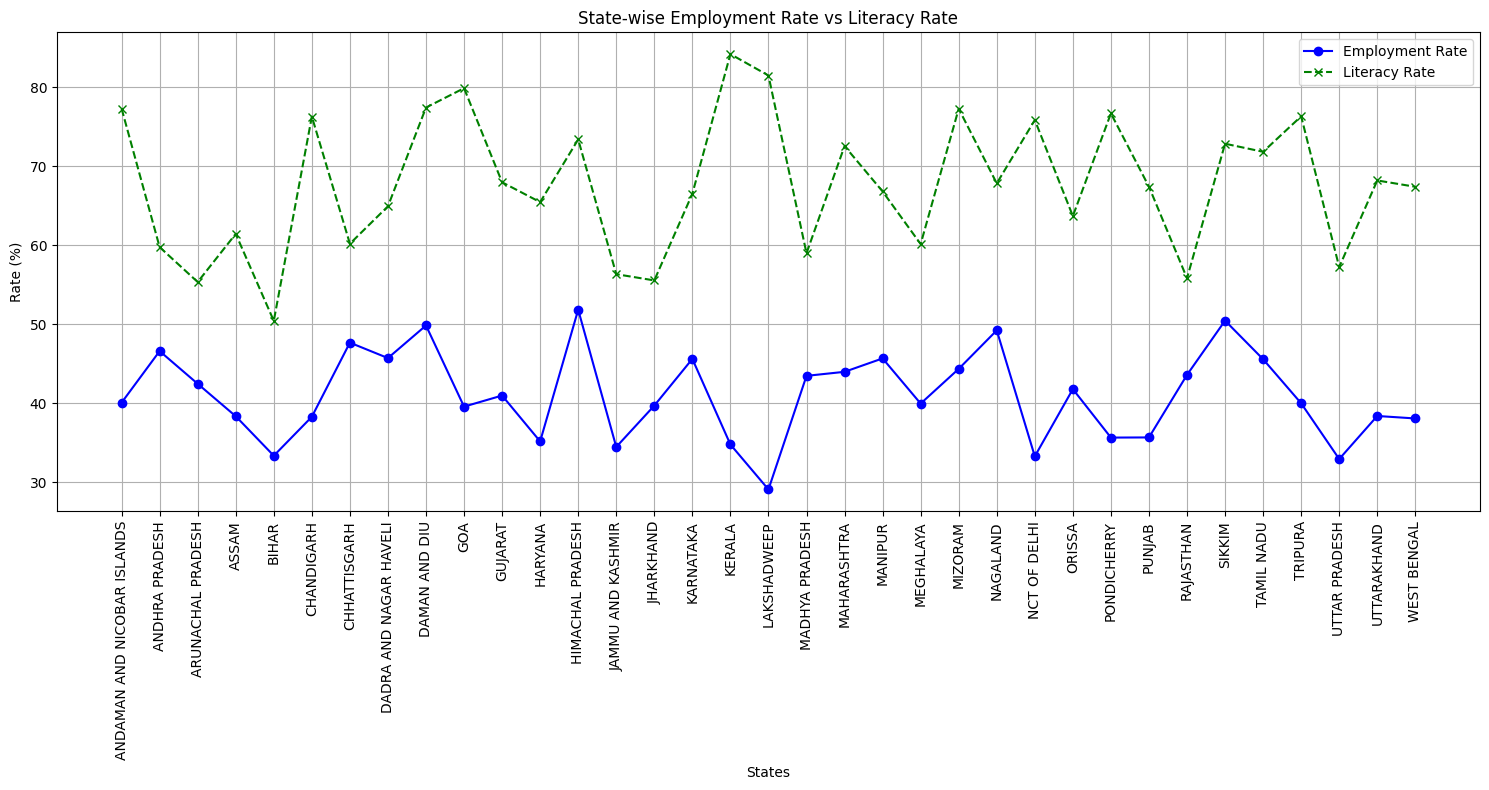


Employment vs Literacy Correlation:
Correlation Coefficient: -0.01

Census Data Analysis Menu:

1. View Overall Census Data

2. View State-wise Population Distribution

3. Compare Male and Female Population

4. Analyze Literacy Rate Trends

5. Analyze Employment Rate Trends

6. Analyze Religion-wise Population Distribution

7. Correlation between Literacy Rate and Employment Rate

8. Visualize Data for a Particular State

9. Exit



Enter your choice:  8
Enter State you want to analyze data of: gujarat


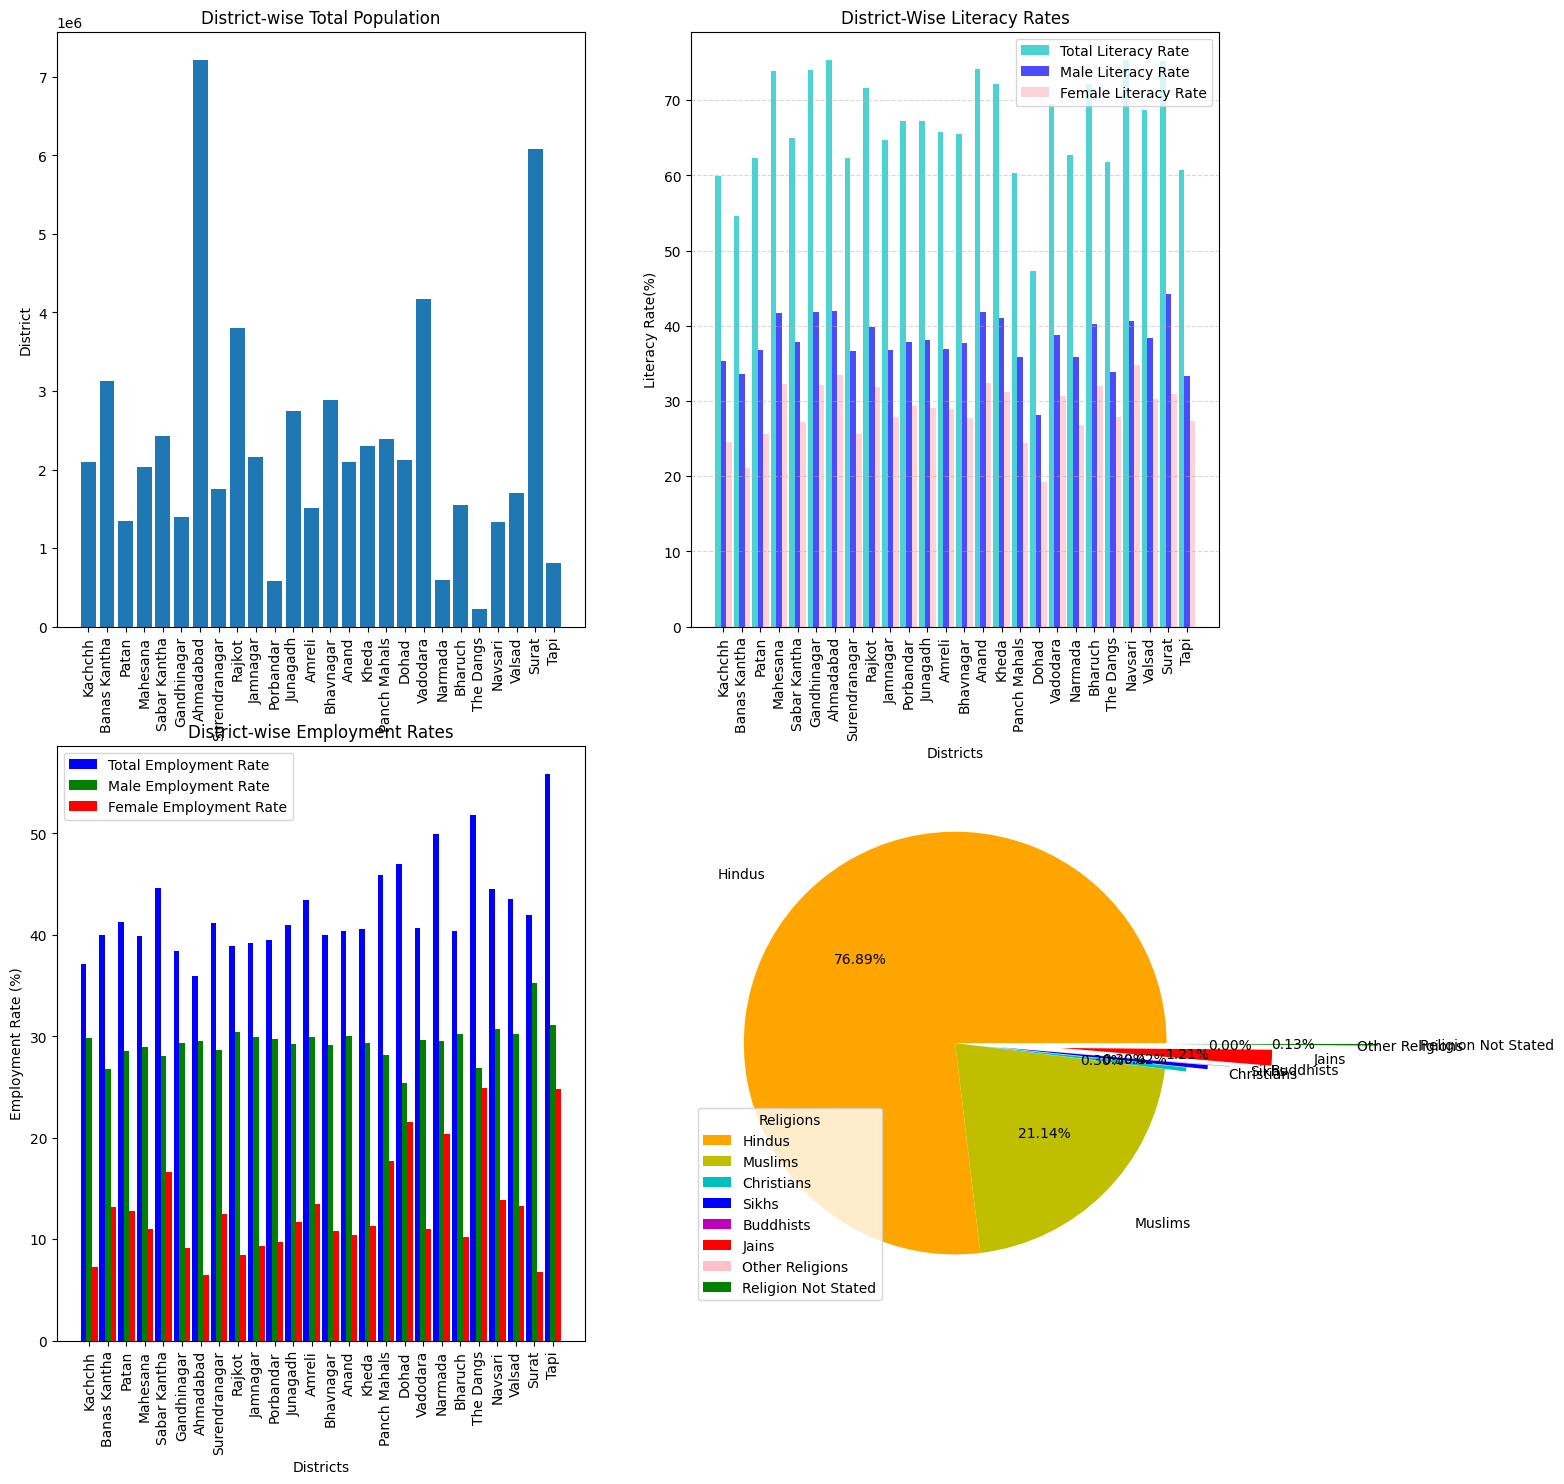


Census Data Analysis Menu:

1. View Overall Census Data

2. View State-wise Population Distribution

3. Compare Male and Female Population

4. Analyze Literacy Rate Trends

5. Analyze Employment Rate Trends

6. Analyze Religion-wise Population Distribution

7. Correlation between Literacy Rate and Employment Rate

8. Visualize Data for a Particular State

9. Exit



Enter your choice:  9



Thank you for using the Census Data Analysis Tool!


In [8]:
class Interaction:
    def menu(self):
        while True:
            print("\nCensus Data Analysis Menu:")
            print("\n1. View Overall Census Data")
            print("\n2. View State-wise Population Distribution")
            print("\n3. Compare Male and Female Population")
            print("\n4. Analyze Literacy Rate Trends")
            print("\n5. Analyze Employment Rate Trends")
            print("\n6. Analyze Religion-wise Population Distribution")
            print("\n7. Correlation between Literacy Rate and Employment Rate")
            print("\n8. Visualize Data for a Particular State")
            print("\n9. Exit")
            
            try:
                n = int(input("\nEnter your choice: "))
                if n == 1:
                    obj_Analyzer.view_overall_census_data()
                elif n == 2:
                    obj_Analyzer.State_wise_Population()
                elif n == 3:
                    obj_Analyzer.male_female_comparision()
                elif n == 4:
                    obj_Analyzer.analyze_literacy_rate()
                elif n == 5:
                    obj_Analyzer.analyze_employment_rate()
                elif n == 6:
                     obj_Analyzer.analyze_religion_distribution()
                elif n == 7:
                    obj_Analyzer.literacy_vs_employment()
                elif n == 8:
                    obj_Analyzer.Visualize_data_for_particular_state()
                elif n == 9:
                    print("\nThank you for using the Census Data Analysis Tool!")
                    break
                else:
                    print("Invalid choice. Please enter a valid option.")
            
            except sqlite3.Error as e:
                print(e)
                print("Invalid input. Please enter a number.")
                
obj_Analyzer = Analyzer()
obj_census=Census()
obj_interaction = Interaction()
obj_interaction.menu() 